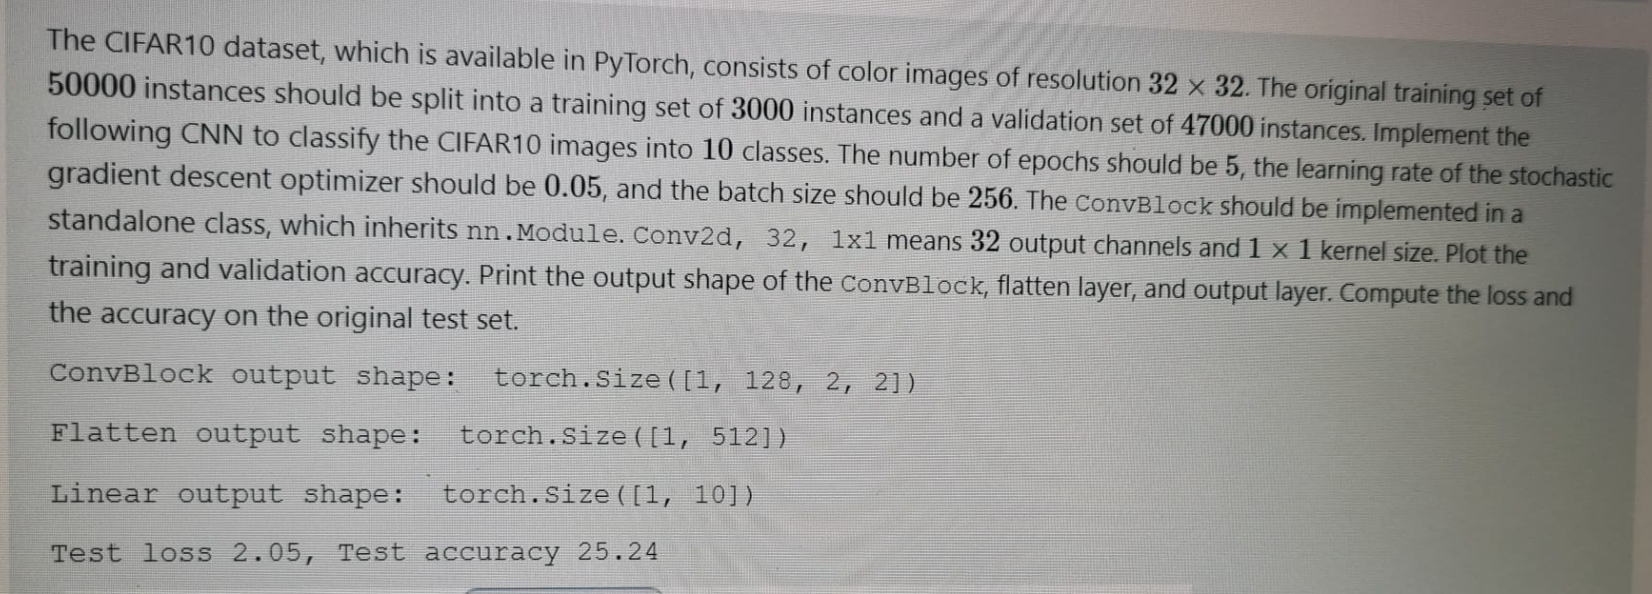

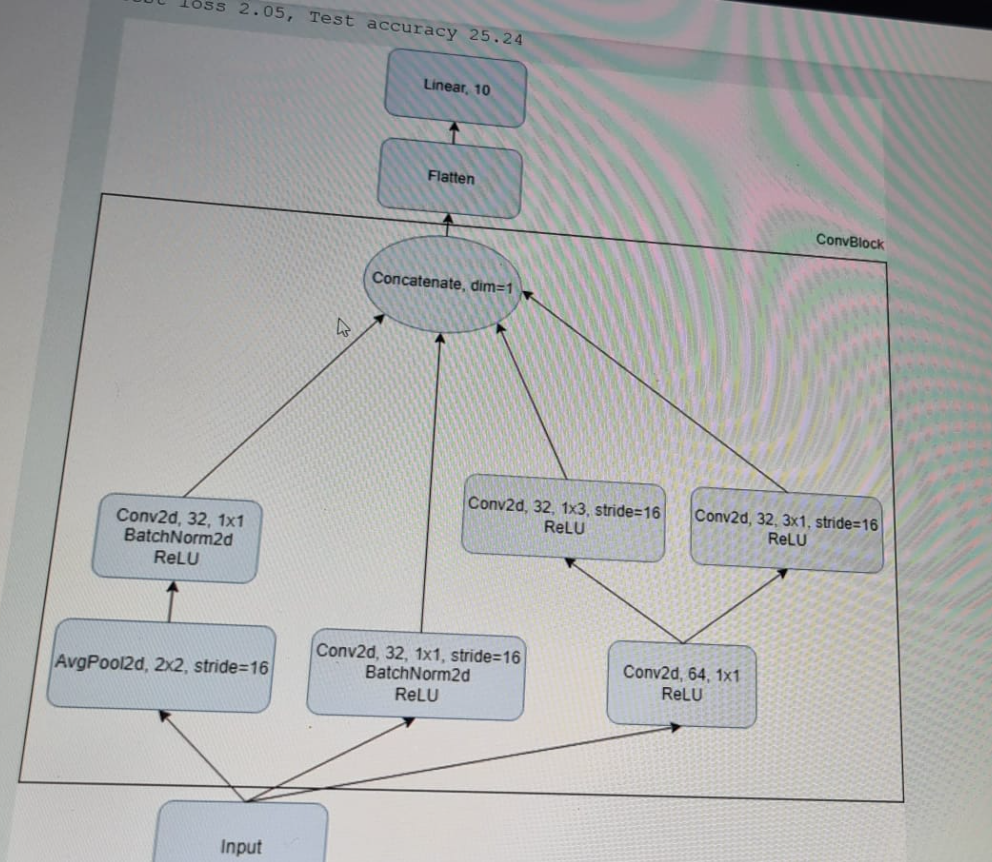

In [ ]:
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.backends.cudnn.deterministic = True

In [ ]:
def load_data_cifar(batch_size, resize=None):
    """Download the Fashion-MNIST dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    cifar_train = torchvision.datasets.CIFAR10(
        root="../data", train=True, transform=trans, download=True)
    cifar_test = torchvision.datasets.CIFAR10(
        root="../data", train=False, transform=trans, download=True)
    cifar_train, cifar_val = torch.utils.data.random_split(cifar_train, [3000, 47000],
                                                           generator=torch.Generator().manual_seed(42))
    return (torch.utils.data.DataLoader(cifar_train, batch_size, shuffle=True,
                            num_workers=2),
            torch.utils.data.DataLoader(cifar_val, batch_size, shuffle=False,
                            num_workers=2),
            torch.utils.data.DataLoader(cifar_test, batch_size, shuffle=False,
                            num_workers=2))

def try_gpu(i=0):
    """Return gpu(i) if exists, otherwise return cpu()."""
    if torch.cuda.device_count() >= i + 1:
        return torch.device(f'cuda:{i}')
    return torch.device('cpu')

def evaluate_accuracy(net, data_iter, loss, device):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples  * 100

def train_epoch(net, train_iter, loss, optimizer, device):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        X, y = X.to(device), y.to(device)
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples  * 100

def train(net, train_iter, val_iter, test_iter, num_epochs, lr, device):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv2d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('Training on', device)
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer, device)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter, loss, device)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(f'Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}')
    test_loss, test_acc = evaluate_accuracy(net, test_iter, loss, device)
    print(f'Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}')

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [ ]:
class ConvBlock(nn.Module):
    """The Residual block of ResNet."""
    def __init__(self, input_channels):
        super().__init__()

        self.avgJS = nn.AvgPool2d(kernel_size=2, stride=16)

        self.convJM = nn.Conv2d(input_channels, 32, kernel_size=1, stride=16)
        self.bnJM = nn.BatchNorm2d(32)

        self.convJD = nn.Conv2d(input_channels, 64, kernel_size=1)


        self.convSS = nn.Conv2d(input_channels, 32, kernel_size=1)
        self.bnSS = nn.BatchNorm2d(32)

        self.convSM = nn.Conv2d(64, 32, kernel_size=(1,3), stride=16)

        self.convSD = nn.Conv2d(64, 32, kernel_size=(3,1), stride=16)




    def forward(self, X):
        Y1 = nn.ReLU()(self.bnSS(self.convSS(self.avgJS(X))))
        Y2 = nn.ReLU()(self.bnJM(self.convJM(X)))
        y  = nn.ReLU()(self.convJD(X))
        Y3 = nn.ReLU()(self.convSM(y))
        Y4 = nn.ReLU()(self.convSD(y))

        Y = torch.cat((Y1, Y2, Y3, Y4), 1)

        return Y

In [ ]:
net = nn.Sequential(ConvBlock(3), nn.Flatten(), nn.Linear(512, 10))

In [ ]:
batch_size, lr, num_epochs = 256, 0.05, 5
train_iter, val_iter, test_iter = load_data_cifar(batch_size)
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(net, train_iter, val_iter, test_iter, num_epochs, lr, try_gpu()) #11 min

100%|██████████| 170498071/170498071 [00:02<00:00, 67168640.83it/s]


Extracting ../data/cifar-10-python.tar.gz to ../data
Files already downloaded and verified
Training on cpu
Epoch 1, Train loss 2.25, Train accuracy 15.20, Validation loss 2.28, Validation accuracy 11.24
Epoch 2, Train loss 2.12, Train accuracy 20.47, Validation loss 2.22, Validation accuracy 17.19
Epoch 3, Train loss 2.07, Train accuracy 23.57, Validation loss 2.16, Validation accuracy 21.01
Epoch 4, Train loss 2.03, Train accuracy 25.30, Validation loss 2.10, Validation accuracy 23.06
Epoch 5, Train loss 2.01, Train accuracy 26.03, Validation loss 2.05, Validation accuracy 25.39
Test loss 2.04, Test accuracy 25.19


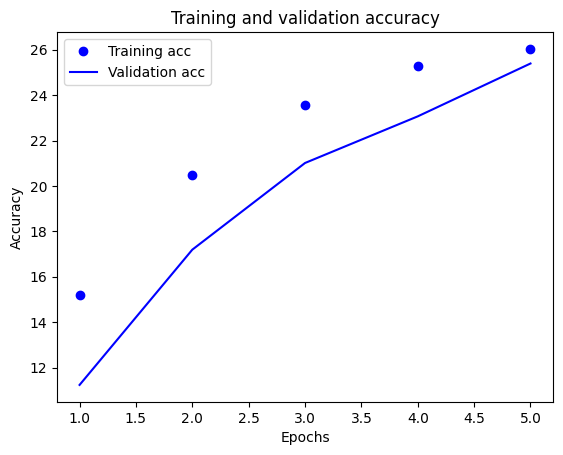

In [ ]:
def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, 'bo', label='Training acc')
    plt.plot(epochs, val_acc_all, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_accuracy(train_acc_all, val_acc_all)

In [ ]:
X = torch.rand(1, 3, 32, 32, device=try_gpu())
for layer in net:
    X = layer(X)
    print(layer.__class__.__name__, 'output shape:\t', X.shape)

ConvBlock output shape:	 torch.Size([1, 128, 2, 2])
Flatten output shape:	 torch.Size([1, 512])
Linear output shape:	 torch.Size([1, 10])


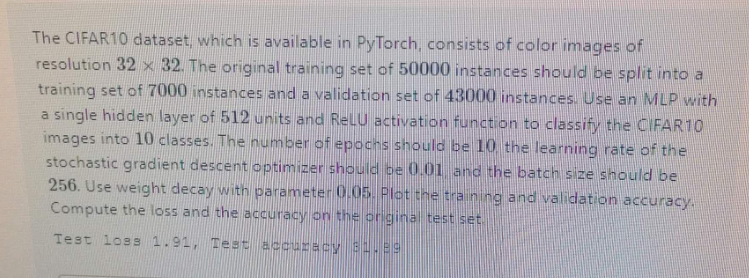

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torchvision
from torchvision import transforms

torch.manual_seed(42)
np.random.seed(42)

100%|██████████| 170498071/170498071 [00:05<00:00, 28594739.14it/s]


Extracting ../data/cifar-10-python.tar.gz to ../data
Files already downloaded and verified


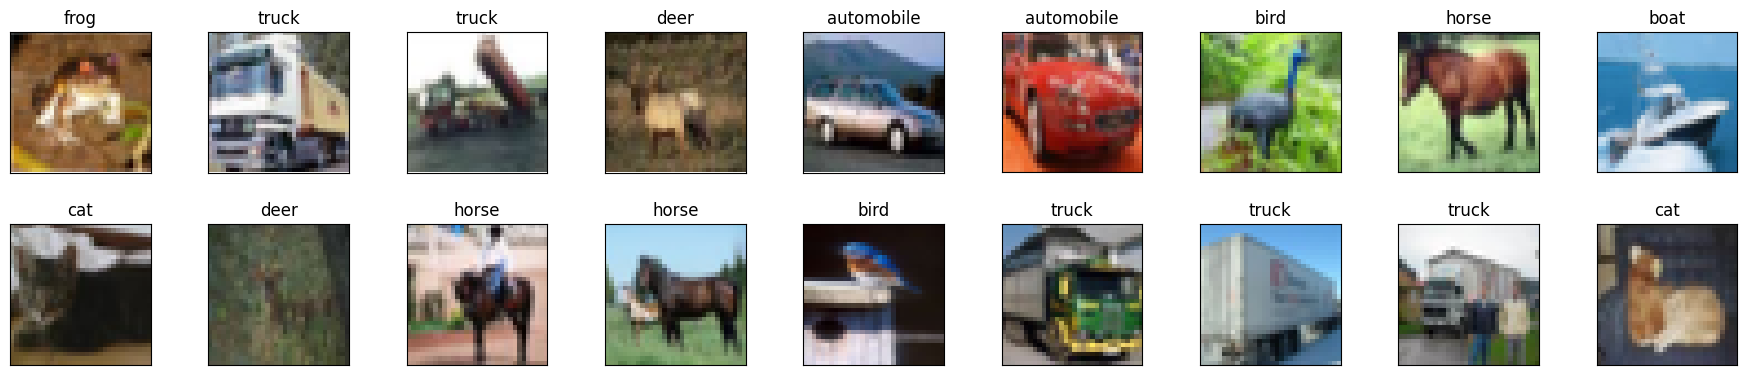

In [ ]:


# `ToTensor()` converts the image data from PIL type to 32-bit floating point
# tensors. It also divides all numbers by 255, so that all pixel values are between
# 0 and 1
trans = transforms.ToTensor()
mnist_train = torchvision.datasets.CIFAR10(
    root="../data", train=True, transform=trans, download=True)
mnist_test = torchvision.datasets.CIFAR10(
    root="../data", train=False, transform=trans, download=True)



def get_fashion_mnist_labels(labels):
    """Return text labels for the Fashion-MNIST dataset."""
    text_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                   'dog', 'frog', 'horse', 'boat', 'truck']
    return [text_labels[int(i)] for i in labels]

def show_images(imgs, num_rows, num_cols, titles=None, scale=2):
    """Plot a list of images."""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    plt.tight_layout()
    axes = axes.flatten()
    #(*[iter(lst)]*3)
    iterimg = iter(imgs)

    for i, (ax, c1,c2,c3) in enumerate(zip(axes, iterimg,iterimg,iterimg)):
        img= torch.stack([c1, c2, c3],2)
        ax.imshow(img)

        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes

X, y = next(iter(torch.utils.data.DataLoader(mnist_train, batch_size=18)))
show_images(X.reshape(54, 32, 32), 2, 9, titles=get_fashion_mnist_labels(y));

In [ ]:
cifar_set = mnist_train
print(cifar_set.data.shape)

from sklearn.model_selection import train_test_split
from torch import nn


cifar_train, cifar_test = train_test_split(cifar_set, test_size=43000, train_size=7000)

(50000, 32, 32, 3)


In [ ]:

def try_gpu(i=0):
    """Return gpu(i) if exists, otherwise return cpu()."""
    if torch.cuda.device_count() >= i + 1:
        return torch.device(f'cuda:{i}')
    return torch.device('cpu')

In [ ]:
def load_data(batch_size, resize=None):
    """Download the CIFAR10 dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    cifar_train = torchvision.datasets.CIFAR10(
        root="../data", train=True, transform=trans, download=True)
    cifar_test = torchvision.datasets.CIFAR10(
        root="../data", train=False, transform=trans, download=True)

    cifar_train, cifar_val = torch.utils.data.random_split(cifar_train, [43000, 7000],
                                                           generator=torch.Generator().manual_seed(42))

    return (torch.utils.data.DataLoader(cifar_train, batch_size, shuffle=True,
                            num_workers=2),
            torch.utils.data.DataLoader(cifar_val, batch_size, shuffle=False,
                            num_workers=2),
            torch.utils.data.DataLoader(cifar_test, batch_size, shuffle=False,
                            num_workers=2))

In [ ]:
def evaluate_accuracy(net, data_iter, device):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples  * 100

def train_epoch(net, train_iter, loss, optimizer, device):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0

    for X, y in train_iter:
        X, y = X.to(device), y.to(device)
        # Compute gradients and update parameters
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples  * 100

def train(net, train_iter, val_iter, loss, num_epochs, optimizer, device):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    net.to(device)
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer, device)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter, device)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(f'Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}')

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [ ]:
net = nn.Sequential(nn.Flatten(),
                    nn.Linear(32*32*3, 512),
                    nn.ReLU(),
                    nn.Linear(512, 10))



def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)


batch_size, lr, num_epochs = 256, 0.01, 10
loss = nn.CrossEntropyLoss()
wd = 0.05
optimizer = torch.optim.SGD(net.parameters(), lr=lr, weight_decay=wd)

train_iter, val_iter, test_iter = load_data(batch_size)
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(net, train_iter, val_iter, loss, num_epochs, optimizer, try_gpu())


Files already downloaded and verified
Files already downloaded and verified
Epoch 1, Train loss 2.26, Train accuracy 15.79, Validation loss 2.21, Validation accuracy 22.79
Epoch 2, Train loss 2.15, Train accuracy 24.30, Validation loss 2.11, Validation accuracy 25.56
Epoch 3, Train loss 2.07, Train accuracy 26.83, Validation loss 2.05, Validation accuracy 28.53
Epoch 4, Train loss 2.02, Train accuracy 28.73, Validation loss 2.01, Validation accuracy 30.04
Epoch 5, Train loss 1.99, Train accuracy 30.09, Validation loss 1.98, Validation accuracy 30.07
Epoch 6, Train loss 1.96, Train accuracy 30.95, Validation loss 1.95, Validation accuracy 31.24
Epoch 7, Train loss 1.94, Train accuracy 31.73, Validation loss 1.94, Validation accuracy 31.43
Epoch 8, Train loss 1.93, Train accuracy 32.18, Validation loss 1.93, Validation accuracy 32.37
Epoch 9, Train loss 1.92, Train accuracy 32.73, Validation loss 1.92, Validation accuracy 32.33
Epoch 10, Train loss 1.91, Train accuracy 33.26, Validation 

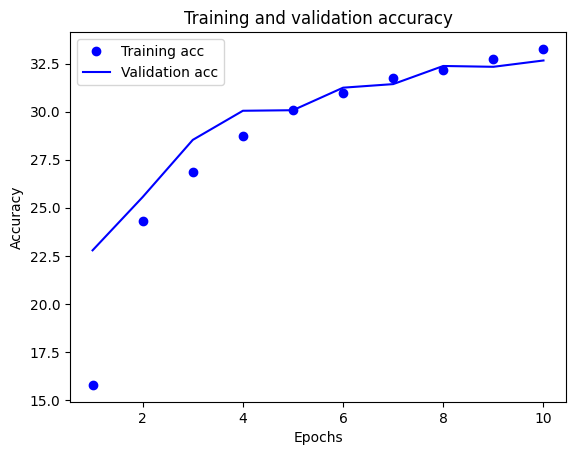

(1.9033334970474243, 32.96)

In [ ]:
def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, 'bo', label='Training acc')
    plt.plot(epochs, val_acc_all, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_accuracy(train_acc_all, val_acc_all)

test_loss, test_acc = evaluate_accuracy(net, test_iter,  device=try_gpu())
test_loss, test_acc

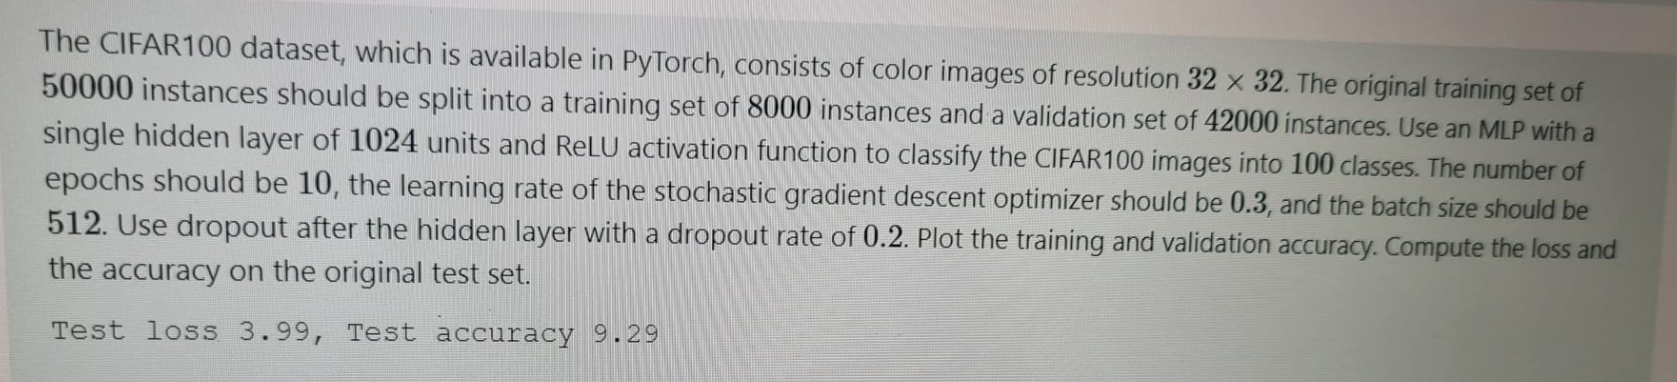

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

In [ ]:
def load_data_cifar(batch_size, resize=None):
    """Download the Fashion-MNIST dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    mnist_train = torchvision.datasets.CIFAR100(
        root="../data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.CIFAR100(
        root="../data", train=False, transform=trans, download=True)
    mnist_train, mnist_val = torch.utils.data.random_split(mnist_train, [8000, 42000],
                                                           generator=torch.Generator().manual_seed(42))
    return (torch.utils.data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_val, batch_size, shuffle=False,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=2))

def train_epoch(net, train_iter, loss, optimizer):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples  * 100

def evaluate_accuracy(net, data_iter):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples  * 100

def train(net, train_iter, val_iter, loss, num_epochs, optimizer):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(f'Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}')

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [ ]:


net = nn.Sequential(nn.Flatten(),
                    nn.Linear(3072, 1024),
                    nn.ReLU(),
                    nn.Dropout(0.2),
                    nn.Linear(1024, 100))

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)

batch_size, lr, num_epochs = 512, 0.3, 10
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr)

train_iter, val_iter, test_iter = load_data_cifar(batch_size)
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(net, train_iter, val_iter, loss, num_epochs, optimizer)

Files already downloaded and verified
Files already downloaded and verified
Epoch 1, Train loss 4.57, Train accuracy 1.75, Validation loss 4.53, Validation accuracy 2.35
Epoch 2, Train loss 4.43, Train accuracy 4.08, Validation loss 4.36, Validation accuracy 4.53
Epoch 3, Train loss 4.34, Train accuracy 4.83, Validation loss 4.33, Validation accuracy 5.01
Epoch 4, Train loss 4.22, Train accuracy 5.73, Validation loss 4.22, Validation accuracy 5.86
Epoch 5, Train loss 4.16, Train accuracy 6.59, Validation loss 4.20, Validation accuracy 6.16
Epoch 6, Train loss 4.09, Train accuracy 7.70, Validation loss 4.11, Validation accuracy 6.94
Epoch 7, Train loss 4.03, Train accuracy 8.96, Validation loss 4.05, Validation accuracy 8.18
Epoch 8, Train loss 3.97, Train accuracy 9.60, Validation loss 4.09, Validation accuracy 7.69
Epoch 9, Train loss 3.93, Train accuracy 10.19, Validation loss 4.11, Validation accuracy 7.64
Epoch 10, Train loss 3.91, Train accuracy 10.40, Validation loss 3.95, Valida

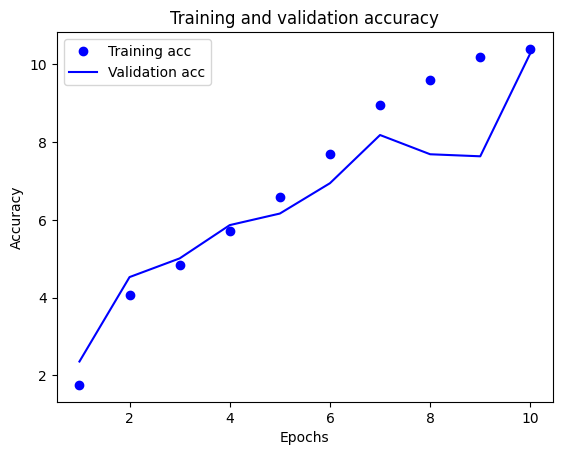

In [ ]:
def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, 'bo', label='Training acc')
    plt.plot(epochs, val_acc_all, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_accuracy(train_acc_all, val_acc_all)



In [ ]:
test_loss, test_acc = evaluate_accuracy(net, test_iter)
print(f'Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}')

Test loss 3.94, Test accuracy 10.69
